# 03 - Evaluation
Reads the saved benchmark results (`results/benchmarks/`); makes **no** API calls.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
from IPython.display import Image, display
from src.evaluation.metrics import generate_report
rs = json.load(open('../results/benchmarks/raw_results.json'))
rep = generate_report(rs, False)
pd.Series({k: v for k, v in rep.items() if not isinstance(v, (dict, list))})

total_tasks           52.0000
success_rate           1.0000
clean_success_rate     1.0000
verified_rate          0.9808
first_try_rate         0.9038
self_fix_rate          1.0000
avg_seconds           28.9000
dtype: float64

## Per-task results

In [2]:
df = pd.DataFrame(rs)[['task_id', 'category', 'difficulty', 'success', 'verified', 'iterations', 'seconds']]
df

,task_id,category,difficulty,success,verified,iterations,seconds
0,sort_01,sorting,easy,True,True,1,37.1
1,sort_02,sorting,easy,True,True,1,51.6
2,sort_03,sorting,medium,True,True,1,24.8
3,sort_04,sorting,easy,True,True,1,58.9
4,search_01,searching,easy,True,True,1,27.9
5,search_02,searching,easy,True,True,1,119.3
6,search_03,searching,medium,True,True,1,18.4
7,string_01,string_manipulation,easy,True,True,1,20.9
8,string_02,string_manipulation,easy,True,True,1,31.1
9,string_03,string_manipulation,medium,True,True,1,22.0


## By category

In [3]:
pd.DataFrame(rep['by_category']).T

,tasks,success_rate,verified_rate
api_calls,10.0,1.0,1.0
data_processing,12.0,1.0,1.0
searching,10.0,1.0,1.0
sorting,10.0,1.0,1.0
string_manipulation,10.0,1.0,0.9


## Plots

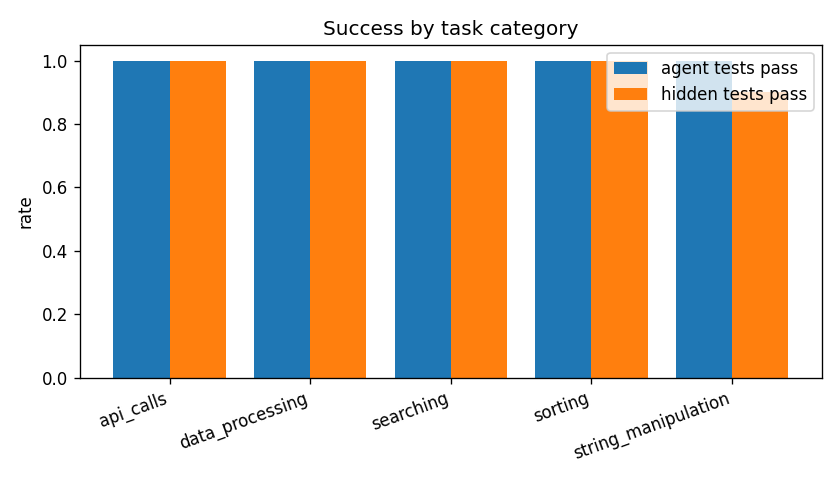

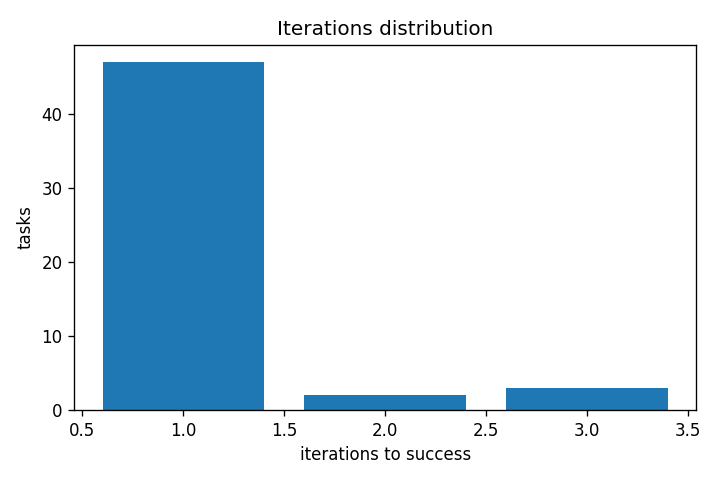

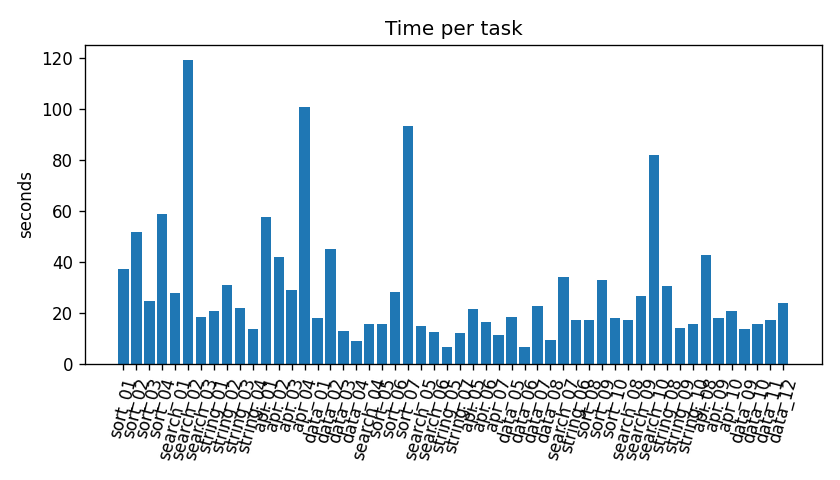

In [4]:
for p in ['success_rate_by_task', 'iterations_distribution', 'time_per_task']:
    display(Image(f'../results/plots/{p}.png'))

## Reading the numbers
- **52 tasks** (10 easy, 26 medium, 16 hard). All 52 pass the agent's own tests; **51/52 pass the hidden reference tests**.
- **First-try 47/52 (95% CI 79-96%)**; the 5 that failed first (`sort_06`, `sort_07`, `data_07`, `search_07`, `search_10`) were all fixed autonomously: **5/5, but the 95% interval is only 57-100%**, so the 70% target is neither proven nor refuted. Hard tasks: 13/16 first-try.
- `search_10` is the first live case of the test-repair path working end to end (`results/case_studies/task_4_test_repair_works.md`).
- **Model confound**: the last 16 tasks ran mostly on `gemini-3.8-flash`, the first 36 mostly on `gemini-3.5-flash-lite`.
- **`string_06` is the self-testing gap**: it passes the agent's own tests but fails the hidden ones (the solution splits on spaces and breaks on `3+2*2`; the agent's tests only used spaced input).
- **Disclosure**: `search_07` and `string_06` were re-run once after tooling fixes (a hard-coding-detector false positive, a missing `import pytest`, a stricter test prompt). The earlier results are kept in `raw_results_run2_36tasks.json`. `search_04` was re-run after the anti-hard-coding changes; run 1 is in `raw_results_run1.json`.
- Latency averages ~30 s (target <30 s), inflated by 503 'high demand' retries on the free tier.
- Results mix several Gemini free-tier models, because the router rotates when one hits its daily quota.

## Next
Grow toward 100 tasks. The current model solves most tasks first time, so more failures need harder tasks (or a weaker model) to tighten the self-fix interval.